In [2]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import csv
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ==========================================
# 2. DATASET PATH
# ==========================================

possible_paths = [
    Path("dataset/SMSSpamCollection"),
    Path("../dataset/SMSSpamCollection")
]

DATASET_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATASET_PATH is None:
    raise FileNotFoundError("SMS Spam Collection dataset not found!")

print("Dataset location:", DATASET_PATH.resolve())
print("Dataset exists:", DATASET_PATH.exists())

Dataset location: C:\Users\sr4me\OneDrive\Documents\Projects\ML_projects\SpamGuard\dataset\SMSSpamCollection
Dataset exists: True


In [4]:
# ==========================================
# 3. LOAD DATASET
# ==========================================

messages = []

with open(DATASET_PATH, "r", encoding="utf-8", newline="") as file:

    reader = csv.reader(file, delimiter="\t")

    for row in reader:

        if len(row) >= 2:

            label = row[0].strip().lower()
            message = row[1].strip()

            messages.append({
                "label": label,
                "message": message
            })

print("Dataset loaded successfully!")
print("Total records:", len(messages))

Dataset loaded successfully!
Total records: 5572


In [5]:
# ==========================================
# 4. INITIAL DATA INSPECTION
# ==========================================

print("FIRST FIVE MESSAGES\n")

for index, item in enumerate(messages[:5], start=1):

    print(f"Message {index}")
    print("Label:", item["label"])
    print("Text:", item["message"])
    print("-" * 70)


# Class distribution

label_counts = Counter(
    item["label"] for item in messages
)

print("\nCLASS DISTRIBUTION")

for label, count in label_counts.items():

    print(f"{label}: {count}")

FIRST FIVE MESSAGES

Message 1
Label: ham
Text: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
----------------------------------------------------------------------
Message 2
Label: ham
Text: Ok lar... Joking wif u oni...
----------------------------------------------------------------------
Message 3
Label: spam
Text: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
----------------------------------------------------------------------
Message 4
Label: ham
Text: U dun say so early hor... U c already then say...
----------------------------------------------------------------------
Message 5
Label: ham
Text: Nah I don't think he goes to usf, he lives around here though
----------------------------------------------------------------------

CLASS DISTRIBUTION
ham: 4825
spam: 747


In [6]:
# ==========================================
# 5. DATASET VALIDATION
# ==========================================

valid_labels = {"ham", "spam"}

invalid_records = []
empty_messages = []
unknown_labels = []

with open(DATASET_PATH, "r", encoding="utf-8", newline="") as file:

    reader = csv.reader(file, delimiter="\t")

    for line_number, row in enumerate(reader, start=1):

        if len(row) < 2:
            invalid_records.append((line_number, row))
            continue

        label = row[0].strip().lower()
        message = row[1].strip()

        if label not in valid_labels:
            unknown_labels.append((line_number, label))

        if not message:
            empty_messages.append(line_number)


print("========== VALIDATION REPORT ==========")

print("Records loaded:", len(messages))
print("Invalid records:", len(invalid_records))
print("Unknown labels:", len(unknown_labels))
print("Empty messages:", len(empty_messages))

print("\nInvalid records:", invalid_records[:5])
print("Unknown labels:", unknown_labels[:5])

========== VALIDATION REPORT ==========
Records loaded: 5572
Invalid records: 0
Unknown labels: 0
Empty messages: 0

Invalid records: []
Unknown labels: []


In [7]:
# ==========================================
# 6. DUPLICATE ANALYSIS
# ==========================================

all_records = [
    (item["label"], item["message"])
    for item in messages
]

unique_records = set(all_records)

print("Total records:", len(all_records))
print("Unique records:", len(unique_records))
print("Duplicate records:", len(all_records) - len(unique_records))

Total records: 5572
Unique records: 5158
Duplicate records: 414


In [8]:
# ==========================================
# 7. REMOVE DUPLICATES
# ==========================================

cleaned_messages = []
seen_records = set()

for item in messages:

    record = (item["label"], item["message"])

    if record not in seen_records:

        cleaned_messages.append(item)
        seen_records.add(record)


messages = cleaned_messages

print("Cleaning completed!")

print("Records before cleaning:", len(all_records))
print("Records after cleaning:", len(messages))
print("Records removed:", len(all_records) - len(messages))

Cleaning completed!
Records before cleaning: 5572
Records after cleaning: 5158
Records removed: 414


In [9]:
# ==========================================
# 8. FINAL DATASET CHECK
# ==========================================

label_counts = Counter(
    item["label"] for item in messages
)

print("Final dataset size:", len(messages))

print("\nClass distribution:")

for label, count in label_counts.items():

    percentage = (count / len(messages)) * 100

    print(f"{label}: {count} ({percentage:.2f}%)")

Final dataset size: 5158

Class distribution:
ham: 4516 (87.55%)
spam: 642 (12.45%)


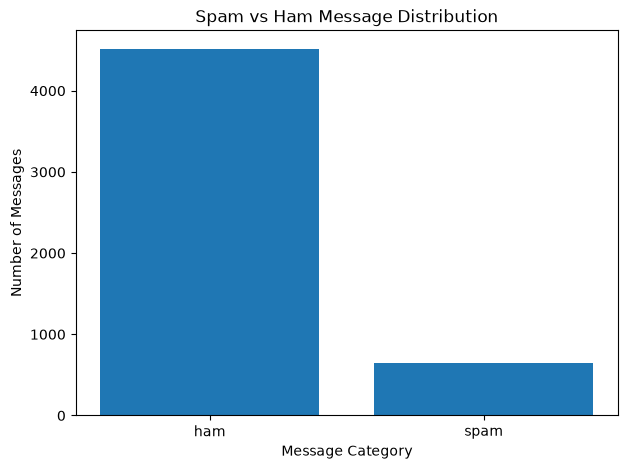

In [10]:
# ==========================================
# 9. CLASS DISTRIBUTION
# ==========================================

label_counts = Counter(
    item["label"] for item in messages
)

labels = list(label_counts.keys())
counts = list(label_counts.values())

plt.figure(figsize=(7, 5))

plt.bar(labels, counts)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [11]:
# ==========================================
# 10. CLASS PERCENTAGES
# ==========================================

total_messages = len(messages)

for label, count in label_counts.items():

    percentage = (count / total_messages) * 100

    print(f"{label.upper()}: {percentage:.2f}%")

HAM: 87.55%
SPAM: 12.45%


In [12]:
# ==========================================
# 11. MESSAGE LENGTH ANALYSIS
# ==========================================

message_lengths = [
    len(item["message"])
    for item in messages
]

print("Average length:", round(np.mean(message_lengths), 2))
print("Minimum length:", min(message_lengths))
print("Maximum length:", max(message_lengths))
print("Median length:", np.median(message_lengths))

Average length: 79.15
Minimum length: 2
Maximum length: 910
Median length: 61.0


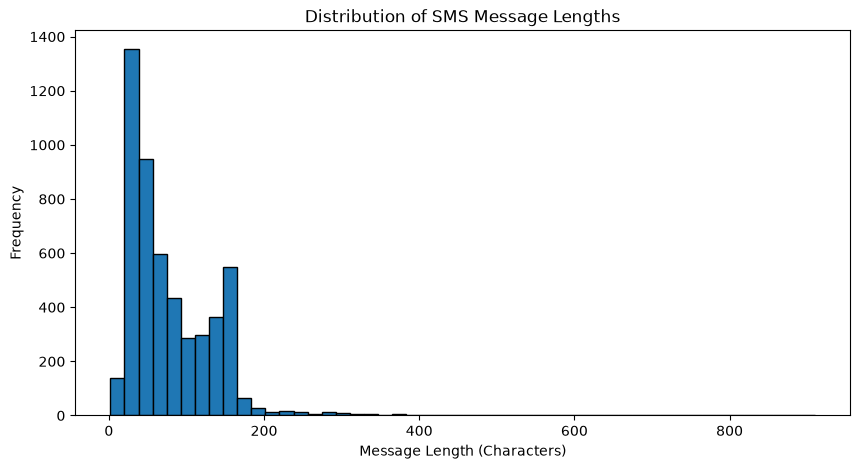

In [13]:
# ==========================================
# 12. MESSAGE LENGTH DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(message_lengths, bins=50, edgecolor="black")

plt.title("Distribution of SMS Message Lengths")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Frequency")

plt.show()

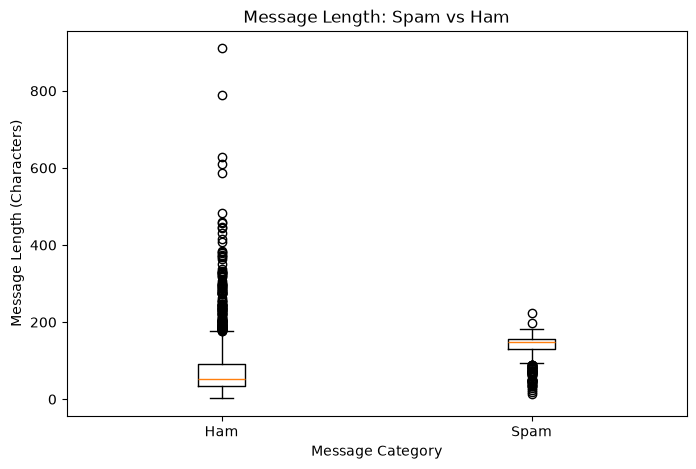

Average ham length: 70.87
Average spam length: 137.41


In [14]:
# ==========================================
# 13. SPAM VS HAM MESSAGE LENGTH
# ==========================================

spam_lengths = [
    len(item["message"])
    for item in messages
    if item["label"] == "spam"
]

ham_lengths = [
    len(item["message"])
    for item in messages
    if item["label"] == "ham"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [ham_lengths, spam_lengths],
    tick_labels=["Ham", "Spam"]
)

plt.title("Message Length: Spam vs Ham")
plt.xlabel("Message Category")
plt.ylabel("Message Length (Characters)")

plt.show()

print("Average ham length:", round(np.mean(ham_lengths), 2))
print("Average spam length:", round(np.mean(spam_lengths), 2))

In [15]:
import re

print("Regex library imported successfully!")

Regex library imported successfully!


In [16]:
# ==========================================
# 14. TEXT PREPROCESSING FUNCTION
# ==========================================

def preprocess_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [17]:
# ==========================================
# 15. TEST PREPROCESSING
# ==========================================

sample_messages = [
    "WINNER!! You have WON £1000. Call NOW!!!",
    "Hey, how are you???",
    "Congratulations!!! Claim your FREE prize NOW."
]

for message in sample_messages:

    cleaned = preprocess_text(message)

    print("Original:", message)
    print("Cleaned: ", cleaned)
    print("-" * 60)

Original: WINNER!! You have WON £1000. Call NOW!!!
Cleaned:  winner you have won 1000 call now
------------------------------------------------------------
Original: Hey, how are you???
Cleaned:  hey how are you
------------------------------------------------------------
Original: Congratulations!!! Claim your FREE prize NOW.
Cleaned:  congratulations claim your free prize now
------------------------------------------------------------


In [18]:
# ==========================================
# 16. PREPROCESS COMPLETE DATASET
# ==========================================

for item in messages:

    item["cleaned_message"] = preprocess_text(
        item["message"]
    )

print("Text preprocessing completed!")

print("\nOriginal vs Cleaned Messages\n")

for item in messages[:5]:

    print("Original:", item["message"])
    print("Cleaned: ", item["cleaned_message"])
    print("-" * 70)

Text preprocessing completed!

Original vs Cleaned Messages

Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned:  go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
----------------------------------------------------------------------
Original: Ok lar... Joking wif u oni...
Cleaned:  ok lar joking wif u oni
----------------------------------------------------------------------
Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned:  free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s
----------------------------------------------------------------------
Original: U dun say so early hor... U c already then say...
Cleaned:  u dun say so early ho

In [19]:
# ==========================================
# 17. CHECK EMPTY CLEANED MESSAGES
# ==========================================

empty_count = sum(
    1 for item in messages
    if not item["cleaned_message"]
)

print("Empty messages after preprocessing:", empty_count)

Empty messages after preprocessing: 2


In [20]:
# ==========================================
# 18. EXTRACT FEATURES AND LABELS
# ==========================================

X = [
    item["cleaned_message"]
    for item in messages
]

y = [
    item["label"]
    for item in messages
]

print("Total messages:", len(X))
print("Total labels:", len(y))

print("\nFirst message:", X[0])
print("First label:", y[0])

Total messages: 5158
Total labels: 5158

First message: go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
First label: ham


In [21]:
# ==========================================
# 19. TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining labels:", len(y_train))
print("Testing labels:", len(y_test))

Training messages: 4126
Testing messages: 1032

Training labels: 4126
Testing labels: 1032


In [22]:
# ==========================================
# 20. IMPORT TF-IDF
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [23]:
# ==========================================
# 21. CREATE TF-IDF VECTORIZER
# ==========================================

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

print("TF-IDF vectorizer created!")

TF-IDF vectorizer created!


In [24]:
# ==========================================
# 22. TF-IDF TRANSFORMATION
# ==========================================

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF transformation completed!

Training matrix shape: (4126, 5000)
Testing matrix shape: (1032, 5000)


In [25]:
# ==========================================
# 23. INSPECT TF-IDF FEATURES
# ==========================================

feature_names = tfidf.get_feature_names_out()

print("Total vocabulary features:", len(feature_names))

print("\nFirst 20 features:")

print(feature_names[:20])

Total vocabulary features: 5000

First 20 features:
['020603' '020603 this' '0800' '08000839402' '08000839402 or'
 '08000930705' '08001950382' '08001950382 or' '0870' '0870 is'
 '08701417012' '08701417012 profit' '08707509020' '08707509020 just'
 '08712300220' '08712300220 quoting' '08712405020' '08712460324'
 '08718720201' '08718726270150gbpmtmsg18']


In [26]:
# ==========================================
# 24. INSPECT ONE MESSAGE
# ==========================================

sample_vector = X_train_tfidf[0]

print("Original message:")
print(X_train[0])

print("\nNumerical representation:")
print(sample_vector)

Original message:
sorry i cant take your call right now it so happens that there r 2waxsto do wat you want she can come and ill get her medical insurance and shell be able to deliver and have basic care im currently shopping for the right medical insurance for her so just give me til friday morning thats when ill see the major person that can guide me to the right insurance

Numerical representation:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 79 stored elements and shape (1, 5000)>
  Coords	Values
  (0, 3670)	0.07244300188837682
  (0, 770)	0.07371811305094338
  (0, 3799)	0.07033148370187547
  (0, 4950)	0.0486340687932835
  (0, 704)	0.05157245964276835
  (0, 3378)	0.23209655613158478
  (0, 2871)	0.05196235435481379
  (0, 2127)	0.04946355948516271
  (0, 3608)	0.10697320110293018
  (0, 1664)	0.1094866654607362
  (0, 3878)	0.10323055747514548
  (0, 3993)	0.06482911205685984
  (0, 1101)	0.055798046882073696
  (0, 4482)	0.07532365701841144
  (0, 4816)	0.03371790259202151
 

In [27]:
# ==========================================
# 25. IMPORT MULTINOMIAL NAIVE BAYES
# ==========================================

from sklearn.naive_bayes import MultinomialNB

print("Multinomial Naive Bayes imported successfully!")

Multinomial Naive Bayes imported successfully!


In [28]:
# ==========================================
# 26. CREATE MODEL
# ==========================================

model = MultinomialNB()

print("Spam classification model created!")

Spam classification model created!


In [29]:
# ==========================================
# 27. TRAIN MODEL
# ==========================================

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [30]:
# ==========================================
# 28. MAKE PREDICTIONS
# ==========================================

y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")

for i in range(10):

    print("Actual:", y_test[i], "| Predicted:", y_pred[i])

Predictions generated successfully!

First 10 predictions:
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham
Actual: ham | Predicted: ham


In [31]:
# ==========================================
# 29. TEST CUSTOM MESSAGES
# ==========================================

custom_messages = [
    "Congratulations! You have won a free iPhone. Claim now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! You have won 50000 cash. Call now to claim your prize.",
    "Can you send me the notes from today's class?",
    "You have been selected for a free vacation. Click here now."
]

# Preprocess messages
cleaned_custom_messages = [
    preprocess_text(message)
    for message in custom_messages
]

# Convert messages into TF-IDF features
custom_vectors = tfidf.transform(cleaned_custom_messages)

# Predict categories
custom_predictions = model.predict(custom_vectors)

# Display results
for message, prediction in zip(custom_messages, custom_predictions):

    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 70)

Message: Congratulations! You have won a free iPhone. Claim now!
Prediction: SPAM
----------------------------------------------------------------------
Message: Hey, are you coming to college tomorrow?
Prediction: HAM
----------------------------------------------------------------------
Message: URGENT! You have won 50000 cash. Call now to claim your prize.
Prediction: SPAM
----------------------------------------------------------------------
Message: Can you send me the notes from today's class?
Prediction: HAM
----------------------------------------------------------------------
Message: You have been selected for a free vacation. Click here now.
Prediction: HAM
----------------------------------------------------------------------


In [32]:
# ==========================================
# 30. IMPORT EVALUATION METRICS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [33]:
# ==========================================
# 31. MODEL PERFORMANCE
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="spam"
)

recall = recall_score(
    y_test, y_pred, pos_label="spam"
)

f1 = f1_score(
    y_test, y_pred, pos_label="spam"
)

print("========== MODEL PERFORMANCE ==========")

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")

========== MODEL PERFORMANCE ==========
Accuracy:  96.80%
Precision: 100.00%
Recall:    74.22%
F1 Score:  85.20%


In [34]:
# ==========================================
# 32. CLASSIFICATION REPORT
# ==========================================

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.74      0.85       128

    accuracy                           0.97      1032
   macro avg       0.98      0.87      0.92      1032
weighted avg       0.97      0.97      0.97      1032



In [35]:
# ==========================================
# 33. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[904   0]
 [ 33  95]]


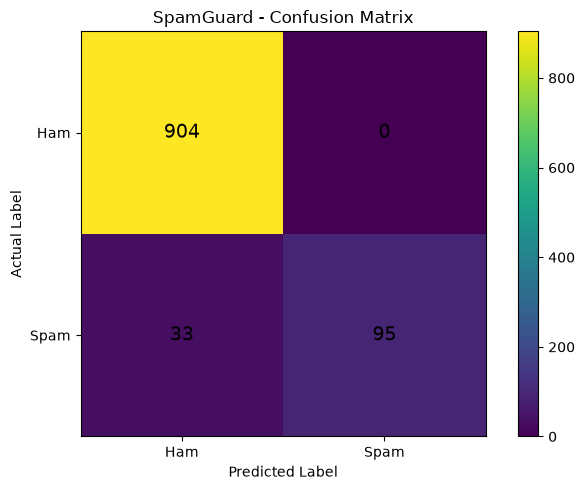

In [36]:
# ==========================================
# 34. CONFUSION MATRIX VISUALIZATION
# ==========================================

plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest")

plt.title("SpamGuard - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# 35. FINAL MODEL SUMMARY
# ==========================================

print("=" * 45)
print("          SPAMGUARD MODEL SUMMARY")
print("=" * 45)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"Vocabulary size  : {len(feature_names)}")

print("-" * 45)

print(f"Accuracy         : {accuracy * 100:.2f}%")
print(f"Precision        : {precision * 100:.2f}%")
print(f"Recall           : {recall * 100:.2f}%")
print(f"F1 Score         : {f1 * 100:.2f}%")

print("=" * 45)

          SPAMGUARD MODEL SUMMARY
Training samples : 4126
Testing samples  : 1032
Vocabulary size  : 5000
---------------------------------------------
Accuracy         : 96.80%
Precision        : 100.00%
Recall           : 74.22%
F1 Score         : 85.20%


In [38]:
# ==========================================
# 36. THRESHOLD TUNING
# ==========================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Get spam probabilities
spam_index = list(model.classes_).index("spam")

spam_probabilities = model.predict_proba(X_test_tfidf)[:, spam_index]

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

print("THRESHOLD PERFORMANCE")
print("-" * 65)

for threshold in thresholds:

    predictions = [
        "spam" if probability >= threshold else "ham"
        for probability in spam_probabilities
    ]

    precision = precision_score(
        y_test, predictions, pos_label="spam", zero_division=0
    )

    recall = recall_score(
        y_test, predictions, pos_label="spam"
    )

    f1 = f1_score(
        y_test, predictions, pos_label="spam"
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

THRESHOLD PERFORMANCE
-----------------------------------------------------------------
Threshold: 0.10 | Precision: 0.782 | Recall: 0.898 | F1: 0.836
Threshold: 0.20 | Precision: 0.973 | Recall: 0.836 | F1: 0.899
Threshold: 0.30 | Precision: 0.991 | Recall: 0.828 | F1: 0.902
Threshold: 0.40 | Precision: 1.000 | Recall: 0.797 | F1: 0.887
Threshold: 0.50 | Precision: 1.000 | Recall: 0.742 | F1: 0.852


In [40]:
# ==========================================
# 37. FINAL CLASSIFICATION THRESHOLD
# ==========================================

SPAM_THRESHOLD = 0.30

spam_index = list(model.classes_).index("spam")

spam_probabilities = model.predict_proba(X_test_tfidf)[:, spam_index]

y_pred_final = [
    "spam" if probability >= SPAM_THRESHOLD else "ham"
    for probability in spam_probabilities
]

print("Selected threshold:", SPAM_THRESHOLD)
print("Final predictions generated!")

Selected threshold: 0.3
Final predictions generated!


In [41]:
# ==========================================
# 38. FINAL MODEL EVALUATION
# ==========================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       904
        Spam       0.99      0.83      0.90       128

    accuracy                           0.98      1032
   macro avg       0.98      0.91      0.94      1032
weighted avg       0.98      0.98      0.98      1032



In [42]:
# ==========================================
# 39. SAVE MODEL AND VECTORIZER
# ==========================================

import joblib

from pathlib import Path

MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, MODEL_DIR / "spam_classifier.pkl")

joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [43]:
# ==========================================
# 40. SAVE CLASSIFICATION THRESHOLD
# ==========================================

joblib.dump(
    SPAM_THRESHOLD,
    MODEL_DIR / "spam_threshold.pkl"
)

print("Classification threshold saved!")

Classification threshold saved!


In [44]:
# ==========================================
# 41. REAL-WORLD MESSAGE TESTING
# ==========================================

test_messages = [

    # Suspicious messages
    "Congratulations! You have won a free iPhone. Claim now!",
    
    "URGENT! Your bank account is blocked. Click here to verify.",
    
    "You have been selected for a free vacation. Call now!",
    
    "Hi beautiful lady, I am in love with you. I will give you a free watch.",
    
    "Congratulations! You won 50000 cash. Send your bank details to claim.",
    
    "Get a loan instantly without documents. Apply now!",

    # Normal messages
    "Hey, are you coming to college tomorrow?",
    
    "Can you send me the notes from today's class?",
    
    "I will call you when I reach home.",
    
    "Happy birthday! Have a wonderful day.",
    
    "Are we meeting at 5 PM today?"
]

In [46]:
# ==========================================
# 42. TEST MODEL ON REAL-WORLD MESSAGES
# ==========================================

cleaned_test_messages = [
    preprocess_text(message)
    for message in test_messages
]

test_vectors = tfidf.transform(cleaned_test_messages)

probabilities = model.predict_proba(test_vectors)

spam_index = list(model.classes_).index("spam")

print("=" * 90)
print("                 SPAMGUARD REAL-WORLD TEST RESULTS")
print("=" * 90)

for message, probability in zip(test_messages, probabilities):

    spam_probability = probability[spam_index]

    prediction = (
        "SPAM"
        if spam_probability >= SPAM_THRESHOLD
        else "HAM"
    )

    print("\nMessage:", message)
    print(f"Spam Probability: {spam_probability * 100:.2f}%")
    print("Prediction:", prediction)
    print("-" * 90)

                 SPAMGUARD REAL-WORLD TEST RESULTS

Message: Congratulations! You have won a free iPhone. Claim now!
Spam Probability: 94.04%
Prediction: SPAM
------------------------------------------------------------------------------------------

Message: URGENT! Your bank account is blocked. Click here to verify.
Spam Probability: 45.72%
Prediction: SPAM
------------------------------------------------------------------------------------------

Message: You have been selected for a free vacation. Call now!
Spam Probability: 62.07%
Prediction: SPAM
------------------------------------------------------------------------------------------

Message: Hi beautiful lady, I am in love with you. I will give you a free watch.
Spam Probability: 1.07%
Prediction: HAM
------------------------------------------------------------------------------------------

Message: Congratulations! You won 50000 cash. Send your bank details to claim.
Spam Probability: 86.57%
Prediction: SPAM
---------------

In [47]:
from sklearn.model_selection import train_test_split

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Subtraining samples:", len(X_subtrain))
print("Validation samples:", len(X_validation))

Subtraining samples: 3300
Validation samples: 826


In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

validation_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_subtrain_tfidf = validation_vectorizer.fit_transform(X_subtrain)

X_validation_tfidf = validation_vectorizer.transform(X_validation)

validation_model = MultinomialNB()

validation_model.fit(X_subtrain_tfidf, y_subtrain)

print("Validation model trained!")

Validation model trained!


In [49]:
import numpy as np

from sklearn.metrics import precision_score, recall_score, f1_score

spam_index = list(validation_model.classes_).index("spam")

validation_probabilities = validation_model.predict_proba(
    X_validation_tfidf
)[:, spam_index]

threshold_results = []

for threshold in np.arange(0.10, 0.61, 0.01):

    predictions = [
        "spam" if p >= threshold else "ham"
        for p in validation_probabilities
    ]

    precision = precision_score(
        y_validation, predictions,
        pos_label="spam",
        zero_division=0
    )

    recall = recall_score(
        y_validation, predictions,
        pos_label="spam",
        zero_division=0
    )

    f1 = f1_score(
        y_validation, predictions,
        pos_label="spam",
        zero_division=0
    )

    threshold_results.append(
        (threshold, precision, recall, f1)
    )

best_result = max(threshold_results, key=lambda x: x[3])

SPAM_THRESHOLD = best_result[0]

print("Best validation threshold:", round(SPAM_THRESHOLD, 2))
print("Precision:", round(best_result[1], 4))
print("Recall:", round(best_result[2], 4))
print("F1-score:", round(best_result[3], 4))

Best validation threshold: 0.16
Precision: 0.9535
Recall: 0.7961
F1-score: 0.8677


In [50]:
# Recreate the final vectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)


# Train the final model

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)


# Evaluate once on untouched test data

spam_index = list(model.classes_).index("spam")

test_probabilities = model.predict_proba(
    X_test_tfidf
)[:, spam_index]

y_pred_final = [
    "spam" if p >= SPAM_THRESHOLD else "ham"
    for p in test_probabilities
]

print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.93      0.85      0.89       128

    accuracy                           0.97      1032
   macro avg       0.96      0.92      0.94      1032
weighted avg       0.97      0.97      0.97      1032



In [51]:
joblib.dump(model, MODEL_DIR / "spam_classifier.pkl")
joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.pkl")
joblib.dump(SPAM_THRESHOLD, MODEL_DIR / "spam_threshold.pkl")

print("Final model, vectorizer and threshold saved!")

Final model, vectorizer and threshold saved!
